# Plotting

**A score says how far a forecast is from the answer key; a picture shows where it went wrong, and in which draws.**

This chapter builds `timegym.plotting`, the two figures behind `run.plot_forecasts()` and `run.plot_errors()`. `plot_forecasts` draws one panel per case: the recent history, what actually happened, the answer key and the forecast, with the case's score on top. `plot_errors` draws one histogram per scenario, of one error per case, so that a poor average can be traced to the draws behind it. Both share the scorecard's look: the colors are defined here, and the [scorecard](13_scorecard.ipynb) imports them.

Below we read a good forecast panel by panel, find the draws a homemade model gets wrong and see why, and watch both figures name a broken forecast instead of hiding it.

**Development notebook.** The collapsed cells are the source of `timegym/plotting.py`; expand them to edit, then follow the [build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp plotting

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

## Build the figures

The shared look comes first, then the pieces of one panel, then the two figures. These cells write `timegym/plotting.py`.

### One look for every figure

Gray dots for observations, a black line for the answer key, blue crosses for the forecast, a dashed hairline at the forecast origin, and the score as a badge in its band's color. The [scorecard](13_scorecard.ipynb) imports these constants, so a change here restyles both. Each mark keeps a descriptive label, such as "Predictive mean", which the tests read; `_KEY_NAMES` turns those labels into the plain words of the figure key.

In [3]:
#| export plotting
from __future__ import annotations
from timegym._internal import positive_int

import textwrap

import numpy as np
import pandas as pd

from timegym import metrics
from timegym.scenarios import scenario_label


# One look for every TimeGym figure, shared with the scorecard: gray dots for
# what was observed, a black line for the answer key, blue crosses for the
# forecast, and a hairline at the forecast origin.
_INK, _MUTED, _SURFACE, _HAIRLINE = "#0b0b0b", "#52514e", "#fcfcfb", "#c3c2b7"
_FORECAST = "#2a78d6"
_ALERT = "#a32020"
_GRID = "#ebeae4"
# Score bands (timegym.scorecard.verdict) with the text color that stays readable on each.
_BAND_COLORS = {"Nails it": ("#0ca30c", "white"), "Good": ("#8fd18f", _INK),
                "Struggles": ("#fab219", _INK), "Fails": ("#d03b3b", "white"), None: ("#52514e", "white")}
_STYLE = {
    "font.family": "DejaVu Sans", "font.size": 9, "text.color": _INK,
    "figure.facecolor": _SURFACE, "axes.facecolor": _SURFACE, "savefig.facecolor": _SURFACE,
    "axes.edgecolor": _HAIRLINE, "axes.labelcolor": _MUTED, "axes.labelsize": 8.5,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": _INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": _GRID, "grid.linewidth": 0.6, "xtick.color": _MUTED, "ytick.color": _MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "ytick.major.size": 0, "xtick.major.size": 3,
    "legend.frameon": False, "legend.fontsize": 8.5, "figure.dpi": 110,
}
# Plain names for the figure key; the artists keep their descriptive labels.
_KEY_NAMES = {
    "Observed context": "Observations", "Held-out observations": "Observations",
    "Known conditional mean": "Answer key",
    "Conditional mean (approx. filter)": "Answer key (approximate filter)",
    "Predictive mean": "Forecast", "Forecast origin": "Forecast origin",
}


### Matplotlib only when drawing

TimeGym imports Matplotlib when a figure is drawn, not when the package is imported, so everything else works without it.

In [4]:
#| export plotting
def _pyplot():
    import matplotlib.pyplot as plt

    return plt

### Cases grouped by scenario

Both figures group a run's cases by scenario position, so two scenarios of the same kind stay apart. An empty run is refused.

In [5]:
#| export plotting
def _groups(run):
    if not run.cases:
        raise ValueError("Cannot plot an empty ForecastRun")
    groups = {}
    for entry in run.cases:
        groups.setdefault(entry.scenario_index, []).append(entry)
    return groups

### A time axis for any index

Dates and periods get a date axis, time differences are shown in seconds, and step numbers stay numbers. Any other ordered labels are spaced evenly and printed as they are, rather than passed off as dates. The forecast origin sits halfway between the last observation and the first date to forecast.

In [6]:
#| export plotting
def _time_coordinates(context_index, future_index, ax):
    """Return coordinates and a midpoint without relying on pandas plot state."""
    indexes = (context_index, future_index)
    if all(isinstance(index, (pd.DatetimeIndex, pd.PeriodIndex)) for index in indexes):
        import matplotlib.dates as mdates

        converted = [index.to_timestamp() if isinstance(index, pd.PeriodIndex) else index for index in indexes]
        coordinates = [mdates.date2num(index.to_pydatetime()) for index in converted]
        timezone = getattr(converted[0], "tz", None)
        locator = mdates.AutoDateLocator(minticks=3, maxticks=6, tz=timezone)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=timezone))
        label = "Time"
    elif all(isinstance(index, pd.TimedeltaIndex) for index in indexes):
        coordinates = [index.total_seconds().to_numpy() for index in indexes]
        label = "Elapsed time (seconds)"
    elif all(pd.api.types.is_numeric_dtype(index.dtype) for index in indexes):
        coordinates = [index.to_numpy(dtype=float) for index in indexes]
        label = "Time step"
    else:
        # A custom model may use ordered nonnumeric labels. Show those labels
        # explicitly on an ordinal axis rather than pretending they are dates.
        labels = list(context_index) + list(future_index)
        coordinates = [np.arange(len(context_index)), np.arange(len(context_index), len(labels))]
        locations = np.unique(np.linspace(0, len(labels) - 1, min(6, len(labels)), dtype=int))
        ax.set_xticks(locations, [str(labels[position]) for position in locations])
        label = "Index label (equally spaced)"
    context_x, future_x = coordinates
    cutoff = context_x[-1] + (future_x[0] - context_x[-1]) / 2
    return context_x, future_x, cutoff, label

### Problems written on the panel

Nothing is left out silently. Whatever a panel can't draw, and every check that failed, is written in red in its lower left corner.

In [7]:
#| export plotting
def _annotate(ax, messages):
    if messages:
        message = "\n".join(textwrap.fill(str(item), width=66) for item in messages)
        ax.text(0.02, 0.02, message, transform=ax.transAxes, va="bottom", ha="left", fontsize=8,
                color=_ALERT, bbox={"facecolor": _SURFACE, "alpha": 0.94, "edgecolor": _HAIRLINE,
                                    "boxstyle": "round,pad=0.35"})


In [8]:
#| export plotting
def _diagnostic_problems(entry):
    return [f"{diagnostic.status} · {diagnostic.name}: {diagnostic.message}"
            for diagnostic in entry.result.diagnostics if diagnostic.failed]

### The answer key, only when it lines up

The answer key is drawn only when its dates, series and shape match the task and every value is finite. Otherwise the panel says why it is missing.

In [9]:
#| export plotting
def _valid_reference(case):
    reference = case.reference
    shape = (len(case.task.future_index), len(case.task.target_names))
    return (reference is not None and reference.index.equals(case.task.future_index)
            and tuple(reference.target_names) == case.task.target_names
            and np.asarray(reference.mean).shape == shape
            and np.isfinite(reference.mean).all())

### One panel per case

A panel shows the recent history, four times as many steps as there are to forecast (`history` changes that, and `'all'` shows everything), then what actually happened, the answer key and the forecast. Above it, a badge gives the case's score for that series: the scorecard's 100 × unavoidable / (unavoidable + avoidable) error, for this one case. Beside the badge come the error against the answer key and the error against what happened.

Without an answer key, as with real data, there is no badge and the one error reads "error vs what happened"; a case without a seed, such as a real-data origin, leaves the seed out of its title. A forecast that fails an output check is not drawn, and a crash leaves no forecast to draw: the panel says which.

In [10]:
#| export plotting
def _run_title(run, scenario_index):
    """The run's plain-words title for a scenario position, if it has one."""
    titles = getattr(run, "titles", None) or []
    return titles[scenario_index] if scenario_index < len(titles) else None


def _reference_spread(case, dimension):
    """Mean variance of the answer key for one series: the unavoidable error."""
    try:
        spread = float(np.mean(np.asarray(case.reference.variance, dtype=float)[:, dimension]))
    except (AttributeError, IndexError, TypeError, ValueError):
        return None
    return spread if np.isfinite(spread) and spread > 0 else None


def _history_start(history, past, horizon):
    """Position of the first past step to draw: the last ``history`` steps (4 x horizon by default)."""
    if isinstance(history, str):
        if history != "all":
            raise ValueError("history must be a positive number of steps, None or 'all'")
        return 0
    shown = 4 * horizon if history is None else positive_int(history, "history")
    return max(0, past - shown)


def _case_header(ax, title, score, details):
    """A bold title over the case's score as a colored badge and its errors in gray."""
    ax.set_title(title, loc="left", pad=19 if score is not None or details else 6)
    badge = None
    if score is not None:
        from timegym.scorecard import verdict

        band = verdict(score)
        fill, ink = _BAND_COLORS[band]
        badge = ax.text(0, 1.035, f" {score:.0f}  {band} ", transform=ax.transAxes, va="bottom",
                        ha="left", fontsize=8, weight="bold", color=ink,
                        bbox={"facecolor": fill, "edgecolor": "none", "boxstyle": "round,pad=0.2"})
    if details and badge is None:
        ax.text(0, 1.035, details, transform=ax.transAxes, va="bottom", ha="left", fontsize=8, color=_MUTED)
    elif details:
        ax.annotate(details, xy=(1, 0), xycoords=badge, xytext=(7, 0), textcoords="offset points",
                    va="bottom", ha="left", fontsize=8, color=_MUTED)


def _draw_case(ax, entry, target, *, show_quantiles, title=None, history=None, title_width=70):
    case = entry.case
    task = case.task
    messages = []
    if target not in task.target_names:
        ax.set_axis_off()
        ax.text(0.5, 0.5, f"Target {target!r} is absent in this case", transform=ax.transAxes, ha="center")
        return
    dimension = task.target_names.index(target)
    start = _history_start(history, len(task.context), len(task.future_index))
    context_x, future_x, cutoff, xlabel = _time_coordinates(task.context.index[start:], task.future_index, ax)
    ax.plot(context_x, task.context.iloc[start:, dimension].to_numpy(), color=_MUTED, alpha=0.8,
            marker=".", markersize=2.6, linestyle="None", label="Observed context")
    observed_valid = (case.observed.index.equals(task.future_index)
                      and tuple(case.observed.columns) == task.target_names
                      and case.observed.shape == (len(future_x), len(task.target_names)))
    if observed_valid:
        observed = case.observed.iloc[:, dimension].to_numpy(dtype=float)
        observed_valid = bool(np.isfinite(observed).all())
    if observed_valid:
        ax.plot(future_x, observed, color=_MUTED, alpha=0.8, marker=".", markersize=2.6,
                linestyle="None", label="Held-out observations")
    else:
        messages.append("Held-out observations violate the evaluation contract; not plotted.")

    reference_valid = _valid_reference(case)
    if reference_valid:
        ax.plot(future_x, case.reference.mean[:, dimension], color=_INK,
                linewidth=1.1, label=("Conditional mean (approx. filter)" if
                             getattr(case.reference, "sampler_kind", None) == "approximate_conditional"
                             else "Known conditional mean"))
    elif case.reference is not None:
        messages.append("Conditional reference is misaligned or nonfinite; not plotted.")

    forecast = entry.forecast
    score, details = None, []
    if forecast is None:
        messages.append("No forecast: model execution failed.")
    else:
        try:
            violations = forecast.validate(task)
        except Exception as exc:
            violations = [{"code": "validation_error", "message": f"{type(exc).__name__}: {exc}"}]
        if violations:
            messages.append("Invalid forecast; predictions not plotted: " + "; ".join(
                f"{violation['code']}: {violation['message']}" for violation in violations))
        else:
            if forecast.point is not None:
                point = np.asarray(forecast.point, dtype=float)[:, dimension]
                ax.plot(future_x, point, color=_FORECAST, marker="x", markersize=3.6,
                        markeredgewidth=0.9, linestyle="None", label="Predictive mean")
                if reference_valid:
                    gap = metrics.mean_reference_mse(case.reference.mean[:, dimension], point)
                    spread = _reference_spread(case, dimension)
                    if spread is not None:  # the scorecard's 0-100 score, for this one case
                        score = 100 * spread / (spread + gap)
                    details.append(f"error vs answer key {gap:.3g}")
                if observed_valid:
                    against = "vs what happened" if details else "error vs what happened"
                    details.append(f"{against} {metrics.mse(observed, point):.3g}")
            else:
                messages.append("No explicit predictive mean supplied; no point predictions plotted.")
            if show_quantiles:
                if forecast.quantiles is not None and len(forecast.levels) >= 2:
                    quantiles = np.asarray(forecast.quantiles, dtype=float)
                    coverage = 100 * (float(forecast.levels[-1]) - float(forecast.levels[0]))
                    ax.fill_between(future_x, quantiles[:, dimension, 0], quantiles[:, dimension, -1],
                                    color=_FORECAST, alpha=0.15, linewidth=0,
                                    label=f"{coverage:g}% marginal interval")
                else:
                    messages.append("Marginal interval unavailable: two explicit quantile levels are required.")

    problems = _diagnostic_problems(entry)
    # Contract failures already have the more specific validation annotation.
    other_problems = [problem for problem in problems if "contract_" not in problem]
    messages.extend(other_problems)
    ax.axvline(cutoff, color=_HAIRLINE, linewidth=0.9, linestyle="--", label="Forecast origin")
    ax.set_xlim(context_x[0], future_x[-1])
    ax.set_xlabel(xlabel)
    ax.set_ylabel(str(target))
    several = len(task.target_names) > 1
    if title is None:
        label = scenario_label(entry.result.scenario, case.manifest.get("parameters"), target_index=dimension)
        seed = "" if entry.result.seed is None else f" · seed {entry.result.seed}"  # real data has none
        title = f"{entry.scenario_index + 1}. {label}{f' · {target}' if several else ''}{seed}"
    else:
        title = f"{title}{f' · {target}' if several else ''} · instance {entry.seed_index + 1}"
    if len(title) > title_width:
        title = textwrap.fill(title, width=title_width, break_long_words=False)
    _case_header(ax, title, score, " · ".join(details))
    _annotate(ax, messages)


### `plot_forecasts`: one row per scenario and series, one column per draw

When a case has several series, each gets its own row. One key above all the panels names the marks. When the run has `titles`, as a scorecard's run does, they name the rows and the columns are numbered by instance. `show_quantiles=True` shades the band between the lowest and the highest quantile, step by step.

In [11]:
#| export plotting
def _figure_key(fig):
    """One key above all panels, in plain words, instead of a legend in each."""
    handles = {}
    for ax in fig.axes:
        for handle, label in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(_KEY_NAMES.get(label, label), handle)
    if handles:
        fig.legend(list(handles.values()), list(handles), loc="outside upper left", ncols=len(handles),
                   markerscale=1.8, handlelength=1.6, columnspacing=1.8, labelcolor=_MUTED)


def plot_forecasts(run, *, show_quantiles=False, figsize=None, history=None):
    """Plot retained forecasts as scenario/target rows and seed columns.

    Each panel uses the scorecard's look: gray dots are observations, the
    black line is the answer key, blue crosses are the forecast. Above it, the
    case's 0-100 score sits in its colored band beside its error against the
    answer key and against what happened. ``history`` is how many past steps
    to show: four times the horizon by default, ``"all"`` for the whole
    context. Bands, when requested, are marginal intervals, never
    simultaneous path regions.
    """
    if not isinstance(show_quantiles, bool):
        raise ValueError("show_quantiles must be a boolean")
    _history_start(history, 1, 1)  # reject a bad value before drawing anything
    groups = _groups(run)
    columns = sorted({entry.seed_index for entry in run.cases})
    rows = []
    lookup = {}
    for scenario_index, entries in groups.items():
        targets = list(dict.fromkeys(target for entry in entries for target in entry.case.task.target_names))
        rows.extend((scenario_index, target) for target in targets)
        for entry in entries:
            key = (scenario_index, entry.seed_index)
            if key in lookup:
                raise ValueError("ForecastRun contains duplicate scenario/seed positions")
            lookup[key] = entry
    plt = _pyplot()
    with plt.rc_context(_STYLE):
        fig, axes = plt.subplots(len(rows), len(columns), squeeze=False,
                                 figsize=figsize or (6 * len(columns), 0.4 + 3.4 * len(rows)), layout="constrained")
        # Wrap long titles to the panel: about ten bold characters per inch.
        title_width = max(24, int(10.5 * fig.get_figwidth() / len(columns)))
        for row_index, (scenario_index, target) in enumerate(rows):
            for column_index, seed_index in enumerate(columns):
                ax = axes[row_index, column_index]
                entry = lookup.get((scenario_index, seed_index))
                if entry is None:
                    ax.set_axis_off()
                    ax.text(0.5, 0.5, "No evaluated case at this position", transform=ax.transAxes, ha="center")
                else:
                    _draw_case(ax, entry, target, show_quantiles=show_quantiles,
                               title=_run_title(run, scenario_index), history=history,
                               title_width=title_width)
        for ax in axes[:-1].flat:  # the time axis is named once, under the last row
            ax.set_xlabel("")
        _figure_key(fig)
        return fig


### `plot_errors`: which draws went wrong

One histogram per scenario, of one whole-case error per draw: the error against the answer key by default, or `metric='mse'` for the error against what happened. A black line marks the median. Every count is a case, never a step, because the steps of one forecast are not independent draws. When a case has no score the figure refuses to draw, unless `missing='annotate'`, which draws the rest and lists the missing cases with the reason.

In [12]:
#| export plotting
def plot_errors(run, metric="mean_reference_mse", *, bins=None, missing="raise", figsize=None):
    """Show distributions of retained whole-case metrics, one row per scenario.

    These are distributions over evaluated cases, not over predictive sample
    draws or dependent coordinates. A black line marks each row's median.
    Scenario positions remain distinct even when their kind strings match.
    Missing scores are never silently dropped.
    """
    groups = _groups(run)
    if not isinstance(metric, str) or not metric:
        raise ValueError("metric must be a nonempty metric name")
    if missing not in {"raise", "annotate"}:
        raise ValueError("missing must be 'raise' or 'annotate'")
    if bins is not None:
        bins = positive_int(bins, "bins")
    values_by_group = {}
    missing_by_group = {}
    for scenario_index, entries in groups.items():
        values, unavailable = [], []
        for entry in entries:
            value = entry.result.metrics.get(metric)
            if isinstance(value, (int, float, np.integer, np.floating)) and np.isfinite(value):
                values.append(float(value))
            else:
                unavailable.append(entry)
        values_by_group[scenario_index], missing_by_group[scenario_index] = values, unavailable
    unavailable = [entry for entries in missing_by_group.values() for entry in entries]
    if unavailable and missing == "raise":
        identities = ", ".join(f"scenario #{entry.scenario_index + 1} seed={entry.result.seed}" for entry in unavailable)
        raise ValueError(f"Metric {metric!r} is missing or nonfinite for {len(unavailable)} case(s): {identities}. "
                         "Use missing='annotate' to display these omissions explicitly.")

    plt = _pyplot()
    with plt.rc_context(_STYLE):
        fig, axes = plt.subplots(len(groups), 1, squeeze=False,
                                 figsize=figsize or (10, 2.6 * len(groups)), layout="constrained")
        label = ("Error against the answer key (MSE)" if metric == "mean_reference_mse" else
                 "Error against what happened (MSE)" if metric == "mse" else metric)
        for ax, (scenario_index, entries) in zip(axes[:, 0], groups.items()):
            values, missing_entries = values_by_group[scenario_index], missing_by_group[scenario_index]
            summary = f"{len(values)} scored / {len(entries)} evaluated cases"
            if values:
                bin_count = bins if bins is not None else max(1, min(20, int(np.ceil(np.sqrt(len(values))))))
                ax.hist(values, bins=bin_count, color=_FORECAST, alpha=0.45, edgecolor=_SURFACE, linewidth=1)
                median = float(np.median(values))
                ax.axvline(median, color=_INK, linewidth=1.1)
                summary = f"median {median:.3g} (black line) · {summary}"
            ax.set_ylabel("Cases")
            titled = _run_title(run, scenario_index)
            process = titled or scenario_label(entries[0].result.scenario,
                                               entries[0].case.manifest.get("parameters"))
            ax.set_title(f"{'' if titled else f'{scenario_index + 1}. '}{process}", loc="left")
            ax.set_title(summary, loc="right", fontsize=8, fontweight="normal", color=_MUTED)
            if missing_entries:
                messages = [f"{len(missing_entries)} case(s) have no finite {metric!r}; they are not in the histogram."]
                for entry in missing_entries:
                    problem = _diagnostic_problems(entry)
                    messages.append(f"seed={entry.result.seed}: {problem[0] if problem else 'metric unavailable'}")
                _annotate(ax, messages)
        axes[-1, 0].set_xlabel(f"{label}, one score per case")
        return fig


## Read a forecast against the answer key

The fitted AR(1) baseline from [Forecasting models](06_forecasting_models.ipynb) forecasts two series 48 steps ahead. Both revert to their own level, 0 and 5, and their shocks are correlated. Here are three draws, with the band from the forecast's 10% quantile to its 90% quantile:

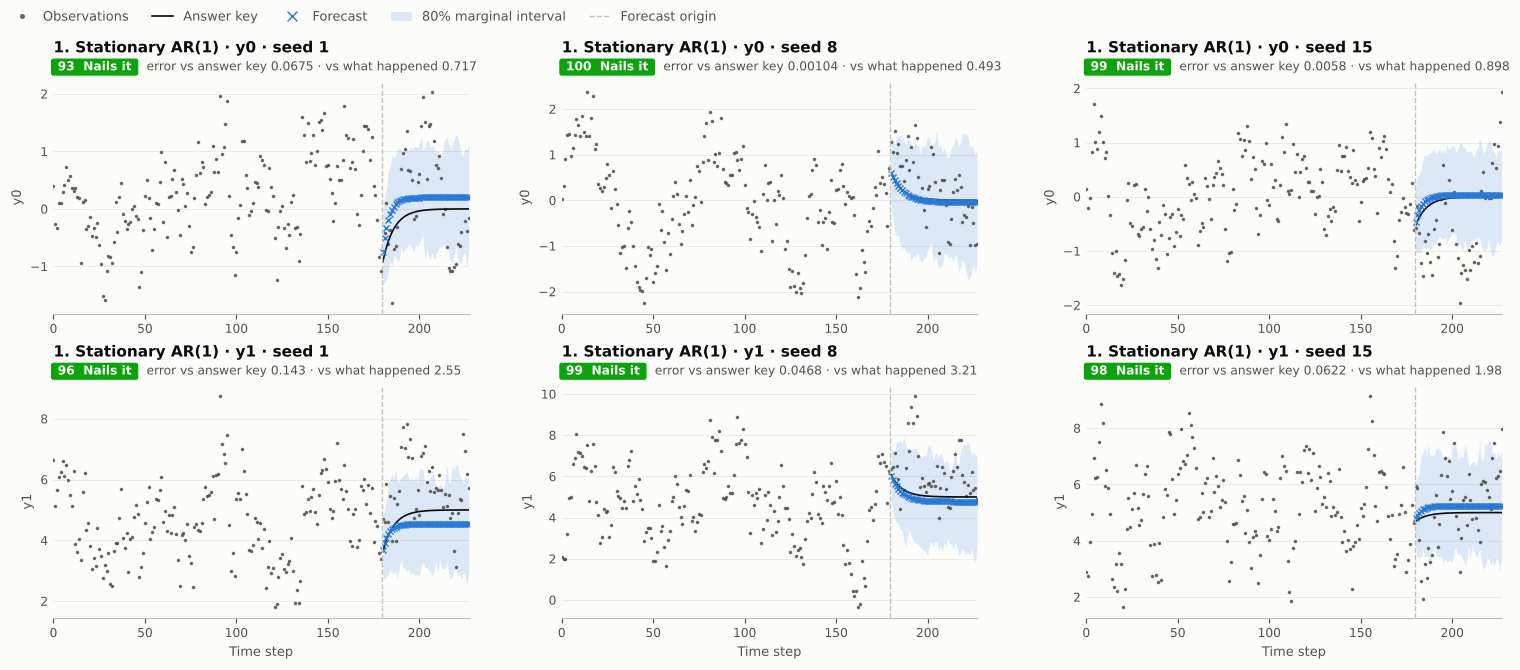

In [13]:
from timegym import GaussianAR1Forecaster, Pipeline, Scenario

two_series = Scenario('ar1', context_length=180, horizon=48, n_targets=2,
                      parameters={'mean': [0., 5.], 'sigma': [.5, 1.], 'phi': .85, 'correlation': .7})
run = Pipeline(GaussianAR1Forecaster(n_samples=96, seed=12)).run([two_series], seeds=[1, 8, 15])
plot_forecasts(run, show_quantiles=True, figsize=(14, 6))
plt.show()

Each row is one series and each column one draw, named by its seed. Left of the dashed line, the gray dots are the history; right of it, what actually happened. The black answer key starts near the last value and decays toward the series' level, as mean reversion should, and the blue crosses follow it closely.

Every badge reads Nails it, from 93 to 100. The gray text beside each badge gives two errors: against the answer key they run from 0.001 to 0.14, against what happened from 0.49 to 3.21, ten to several hundred times larger. The difference is the noise still to come, which no forecaster could know, and that is why the score is measured against the answer key. The band is marginal: at each step about 80% of outcomes should fall inside it, which is not the same as the whole path staying inside.

## Find the draws a model gets wrong

An average over many draws can hide a few bad ones. Here is a model of the kind you might write for prices: it measures the history's average growth rate in logs and carries it forward. We test it on 20 draws of a random walk that starts at 30. For a random walk the answer key stays flat at the last value, because the next shock is as likely to go up as down.

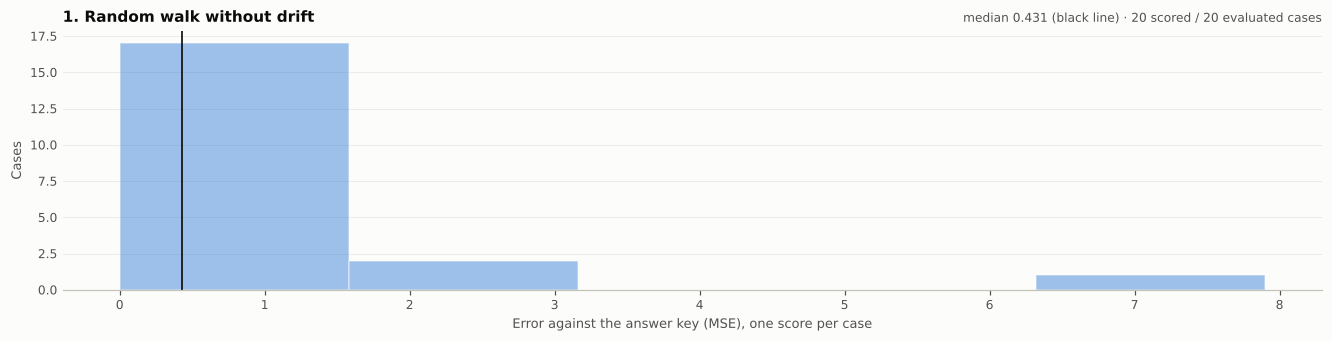

In [14]:
class LogGrowth:
    """Carry the history's average growth rate, measured in logs, forward."""

    def fit(self, context):
        self.columns_ = context.columns
        with np.errstate(invalid='ignore'):  # the log of a negative value is NaN, without a warning
            logs = np.log(context.to_numpy(dtype=float))
        self.last_, self.growth_ = logs[-1], np.diff(logs, axis=0).mean(axis=0)
        return self

    def predict(self, future_index):
        steps = np.arange(1, len(future_index) + 1)[:, None]
        return pd.DataFrame(np.exp(self.last_ + steps * self.growth_), index=future_index, columns=self.columns_)


walk = Scenario('random_walk', context_length=120, horizon=24, parameters={'intercept': 30.})
walk_run = Pipeline(LogGrowth()).run([walk], instances=20)
plot_errors(walk_run, figsize=(12, 3))
plt.show()

Most draws are close: the median error against the answer key is 0.431 (the black line), and 17 of the 20 are below 1.6. Two more are below 3.2, and one is near 8. The run keeps every case with its seed, so we can rank the draws and look at both ends:

In [15]:
draws = pd.DataFrame([{'seed': entry.result.seed,
                       'history ends at': entry.case.task.context.iloc[-1, 0],
                       'error against the answer key': entry.result.metrics['mean_reference_mse'],
                       'error against what happened': entry.result.metrics['mse']}
                      for entry in walk_run.cases]).set_index('seed').sort_values('error against the answer key')
assert (draws['history ends at'].tail(3) > 39).all()  # the three worst draws all climbed from 30 to above 39
loudest = draws['error against what happened'].idxmax()
print(f"Against what happened, the worst draw is seed {loudest} "
      f"({draws.loc[loudest, 'error against what happened']:.1f}), though its error against the answer key "
      f"is only {draws.loc[loudest, 'error against the answer key']:.2f}.")
pd.concat([draws.head(3), draws.tail(3)]).round(2)

Against what happened, the worst draw is seed 4 (78.5), though its error against the answer key is only 0.13.


,history ends at,error against the answer key,error against what happened
seed,,,
19,29.67,0.00,3.40
8,29.03,0.01,1.73
18,29.01,0.01,5.47
0,39.62,1.83,8.04
16,41.19,2.58,42.29
15,48.00,7.90,11.32


The three best draws ended within 1 of their start at 30, so their growth rate is close to zero and the forecast is as flat as the answer key. The three worst climbed to between 39.6 and 48, and the model reads the climb as growth that will continue. The model's average growth in logs depends only on where the history starts and ends, so the further a walk happened to climb, the steeper the trend the model invents. Ranking by the error against what happened would point at the wrong draw: seed 4's walk jumped after the forecast was made, which no forecaster could know.

Here are the best and the worst draw, regenerated from their seeds:

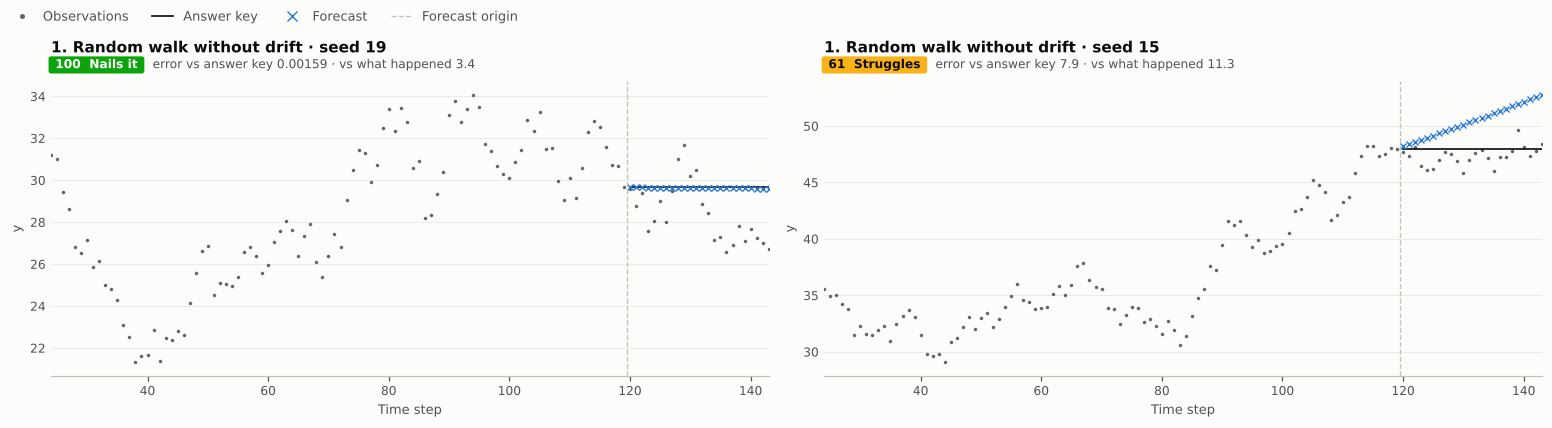

In [16]:
best, worst = draws.index[0], draws.index[-1]
plot_forecasts(Pipeline(LogGrowth()).run([walk], seeds=[best, worst]), figsize=(14, 3.8))
plt.show()

Seed 19 ended at 29.7, near its start, and its forecast lies on the flat answer key: 100, Nails it. Seed 15 climbed to 48, and its forecast keeps climbing, to about 53, while the answer key stays at 48: 61, Struggles. On a random walk, past growth says nothing about the next move, so this model is worst on exactly the walks that moved most.

## A broken forecast is named, not hidden

Start the same 20 walks at 20 instead of 30. The shocks are the same, so every walk is 10 lower, and two of them now dip below zero, where the log is undefined. The model returns NaN for those two draws and raises no error. `plot_errors` refuses to draw a histogram that would quietly leave them out:

In [17]:
lower = Scenario('random_walk', context_length=120, horizon=24, parameters={'intercept': 20.})
low_run = Pipeline(LogGrowth()).run([lower], instances=20)
try:
    plot_errors(low_run)
    refusal = None
except ValueError as error:
    refusal = error
assert refusal is not None  # two draws have no score, so the figure refuses
print(refusal)

Metric 'mean_reference_mse' is missing or nonfinite for 2 case(s): scenario #1 seed=5, scenario #1 seed=10. Use missing='annotate' to display these omissions explicitly.


`missing='annotate'` would draw the histogram anyway, with a note listing the missing draws and why. The forecast panels of those two draws show what went wrong:

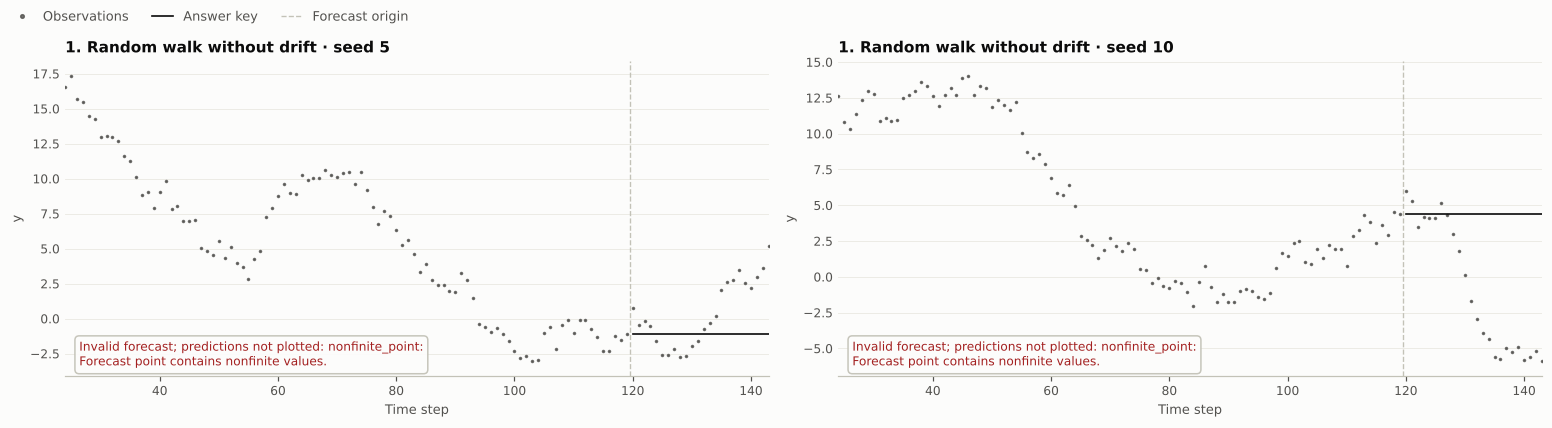

In [18]:
missing = [entry.result.seed for entry in low_run.cases if 'mean_reference_mse' not in entry.result.metrics]
plot_forecasts(Pipeline(LogGrowth()).run([lower], seeds=missing), figsize=(14, 3.8))
plt.show()

Both walks dip below zero inside the window shown. Each panel still draws the history, what happened and the answer key, and in place of the crosses it names the failed check: the forecast contains values that aren't finite. The same failure makes `report.assert_passed()` fail a build ([Reports and replay](10_reports_and_replay.ipynb)).

**Limits.** A panel shows one draw, and a histogram of 20 draws is a rough picture of the spread: compare two models on more draws before trusting a difference you see. The shaded band is marginal, step by step, not a region the whole path stays inside. Both figures draw what the run kept; they never refit the model.

## Change one thing

- Pass `history='all'` to the last `plot_forecasts` call, to see each walk from its start at 20.
- Draw the error against what happened instead, `plot_errors(walk_run, metric='mse')`: does the same draw stand out?
- Draw `plot_errors(low_run, missing='annotate')` to see the note on the two missing draws.
- Give the walk a drift (`parameters={'intercept': 30., 'drift': 0.1}`): which draws does `LogGrowth` get wrong now?

**Next:** [12 · Package](12_package.ipynb) shows which notebook owns each public name. The [Quick start](00_quick_start.ipynb) uses both figures to look behind a scorecard's score.